In [22]:
import warnings
warnings.filterwarnings('ignore')

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVR
from sklearn.metrics import mean_squared_error, mean_absolute_error

print("Đã import thành công các thư viện cần thiết!")


Đã import thành công các thư viện cần thiết!


In [23]:
# 1. Đọc tệp CSV và chỉ sử dụng 2 thuộc tính Date và Close
csv_path = 'BT10.622092301_amazon_stock_price.csv' if os.path.exists('BT10.622092301_amazon_stock_price.csv') else os.path.join('btth', '10', 'BT10.622092301_amazon_stock_price.csv')
data = pd.read_csv(csv_path)

# Chỉ giữ lại 2 cột Date và Close
data = data[['Date', 'Close']]

print("=== 5 DÒNG ĐẦU TIÊN CỦA BỘ DỮ LIỆU ===")
display(data.head())

print("\n=== THÔNG TIN TỔNG QUAN BỘ DỮ LIỆU ===")
data.info()


=== 5 DÒNG ĐẦU TIÊN CỦA BỘ DỮ LIỆU ===


,Date,Close
0,2019-09-23,89.264999
1,2019-09-24,87.080498
2,2019-09-25,88.416496
3,2019-09-26,86.991997
4,2019-09-27,86.272499



=== THÔNG TIN TỔNG QUAN BỘ DỮ LIỆU ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1007 entries, 0 to 1006
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Date    1007 non-null   object 
 1   Close   1007 non-null   float64
dtypes: float64(1), object(1)
memory usage: 15.9+ KB


In [24]:
# 2. Tiền xử lý dữ liệu:
# - Chuyển Date sang datetime và sắp xếp tăng dần theo thời gian
data['Date'] = pd.to_datetime(data['Date'])
data.sort_values('Date', inplace=True)
data.reset_index(drop=True, inplace=True)

# - Chuyển Date sang số nguyên (ordinal) để mô hình hiểu được thời gian
data['Date_ordinal'] = data['Date'].map(pd.Timestamp.toordinal)

print("=== DỮ LIỆU SAU KHI CHUYỂN DATE SANG SỐ NGUYÊN (ORDINAL) ===")
display(data.head())

# - Áp dụng chuẩn hóa (standardization) cho Date_ordinal và Close
scaler_x = StandardScaler()
scaler_y = StandardScaler()

X_scaled = scaler_x.fit_transform(data[['Date_ordinal']])
y_scaled = scaler_y.fit_transform(data[['Close']]).ravel()

print(f"\nKích thước tập dữ liệu: {X_scaled.shape[0]} mẫu")
print(f"X_scaled (Date): mean = {X_scaled.mean():.4f}, std = {X_scaled.std():.4f}")
print(f"y_scaled (Close): mean = {y_scaled.mean():.4f}, std = {y_scaled.std():.4f}")


=== DỮ LIỆU SAU KHI CHUYỂN DATE SANG SỐ NGUYÊN (ORDINAL) ===


,Date,Close,Date_ordinal
0,2019-09-23,89.264999,737325
1,2019-09-24,87.080498,737326
2,2019-09-25,88.416496,737327
3,2019-09-26,86.991997,737328
4,2019-09-27,86.272499,737329



Kích thước tập dữ liệu: 1007 mẫu
X_scaled (Date): mean = 0.0000, std = 1.0000
y_scaled (Close): mean = -0.0000, std = 1.0000


In [25]:
# 3. Huấn luyện mô hình trên toàn bộ dữ liệu (không chia train/test) với 4 loại kernel
models = {
    'SVR Linear (C=100)': SVR(kernel='linear', C=100),
    'SVR RBF 1 (C=100, eps=0.0001, gamma=10)': SVR(kernel='rbf', C=100, epsilon=0.0001, gamma=10),
    'SVR RBF 2 (C=1500000, eps=1e-7, gamma=100)': SVR(kernel='rbf', C=1500000, epsilon=0.0000001, gamma=100, max_iter=300000),
    'SVR Poly degree 3 (C=100, eps=0.0001)': SVR(kernel='poly', degree=3, C=100, epsilon=0.0001)
}

predictions = {}
results = []

print("=== BẮT ĐẦU HUẤN LUYỆN CÁC MÔ HÌNH SVR ===")
for name, model in models.items():
    print(f"Đang huấn luyện mô hình: {name}...")
    model.fit(X_scaled, y_scaled)
    
    # Dự đoán trên thang đo chuẩn hóa rồi nghịch đảo về thang đo giá gốc USD
    pred_scaled = model.predict(X_scaled)
    pred_orig = scaler_y.inverse_transform(pred_scaled.reshape(-1, 1)).ravel()
    predictions[name] = pred_orig
    
    # Tính RMSE và MAE
    rmse = np.sqrt(mean_squared_error(data['Close'], pred_orig))
    mae = mean_absolute_error(data['Close'], pred_orig)
    results.append({'Mô hình': name, 'RMSE': rmse, 'MAE': mae})

results_df = pd.DataFrame(results)
print("\nĐã hoàn thành huấn luyện tất cả 4 mô hình!")


=== BẮT ĐẦU HUẤN LUYỆN CÁC MÔ HÌNH SVR ===
Đang huấn luyện mô hình: SVR Linear (C=100)...
Đang huấn luyện mô hình: SVR RBF 1 (C=100, eps=0.0001, gamma=10)...
Đang huấn luyện mô hình: SVR RBF 2 (C=1500000, eps=1e-7, gamma=100)...
Đang huấn luyện mô hình: SVR Poly degree 3 (C=100, eps=0.0001)...

Đã hoàn thành huấn luyện tất cả 4 mô hình!


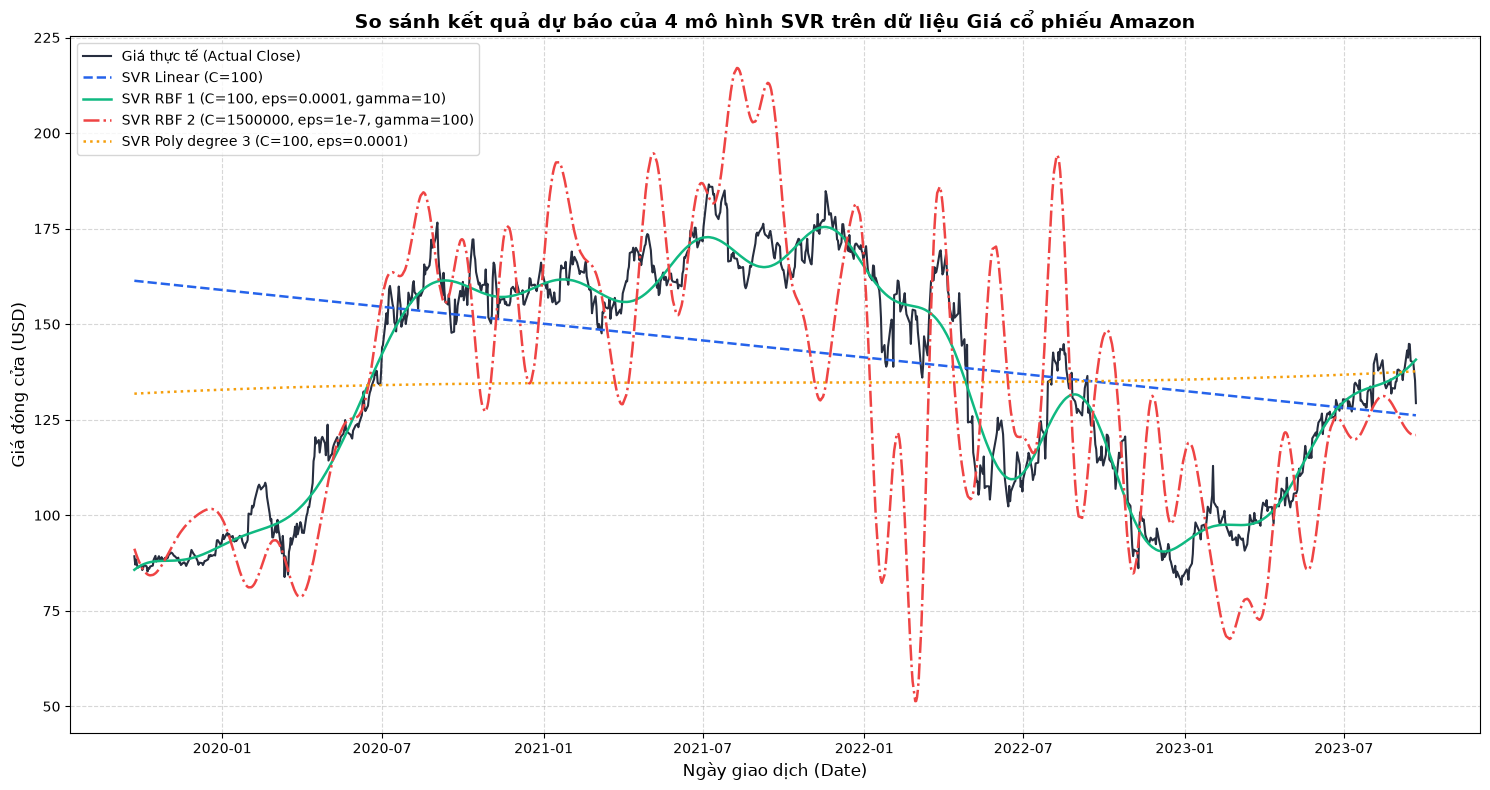

In [26]:
# 4. Vẽ biểu đồ trực quan kết quả của các mô hình trên bộ dữ liệu
plt.figure(figsize=(15, 8))

# Dữ liệu thực tế
plt.plot(data['Date'], data['Close'], color='#0f172a', label='Giá thực tế (Actual Close)', linewidth=1.5, alpha=0.9)

# Đường dự đoán của 4 mô hình
colors = ['#2563eb', '#10b981', '#ef4444', '#f59e0b']
linestyles = ['--', '-', '-.', ':']

for (name, pred), color, ls in zip(predictions.items(), colors, linestyles):
    plt.plot(data['Date'], pred, label=name, color=color, linestyle=ls, linewidth=1.8)

plt.title('So sánh kết quả dự báo của 4 mô hình SVR trên dữ liệu Giá cổ phiếu Amazon', fontsize=14, fontweight='bold')
plt.xlabel('Ngày giao dịch (Date)', fontsize=12)
plt.ylabel('Giá đóng cửa (USD)', fontsize=12)
plt.legend(loc='upper left', fontsize=10)
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()


In [27]:
# 5. Bảng so sánh RMSE và Nhận xét, đánh giá các mô hình
print("=== BẢNG CHỈ SỐ RMSE VÀ MAE CỦA CÁC MÔ HÌNH SVR ===")
display(results_df)

rmse_lin = results_df.loc[results_df['Mô hình'] == 'SVR Linear (C=100)', 'RMSE'].values[0]
rmse_poly = results_df.loc[results_df['Mô hình'] == 'SVR Poly degree 3 (C=100, eps=0.0001)', 'RMSE'].values[0]
rmse_rbf1 = results_df.loc[results_df['Mô hình'] == 'SVR RBF 1 (C=100, eps=0.0001, gamma=10)', 'RMSE'].values[0]
rmse_rbf2 = results_df.loc[results_df['Mô hình'] == 'SVR RBF 2 (C=1500000, eps=1e-7, gamma=100)', 'RMSE'].values[0]

print(f'''
=== NHẬN XÉT VÀ ĐÁNH GIÁ CHI TIẾT CÁC MÔ HÌNH ===

1. Mô hình SVR Linear (C=100):
   - RMSE = {rmse_lin:.4f} USD.
   - Hàm nhân tuyến tính tạo ra một đường thẳng đơn điệu, không thể nắm bắt được các biến động uốn lượn phức tạp của chuỗi giá cổ phiếu. Do đó sai số lớn nhất.

2. Mô hình SVR Poly degree 3 (C=100, eps=0.0001):
   - RMSE = {rmse_poly:.4f} USD.
   - Đa thức bậc 3 có độ cong tốt hơn đường thẳng tuyến tính, nắm bắt được xu hướng tăng rồi giảm chung của thị trường, tuy nhiên vẫn quá cứng nhắc và không thể bám sát các chu kỳ ngắn hạn.

3. Mô hình SVR RBF 1 (C=100, eps=0.0001, gamma=10):
   - RMSE = {rmse_rbf1:.4f} USD (THẤP NHẤT - HIỆU QUẢ TỐT NHẤT).
   - Nhân RBF (Gaussian) với C=100 và gamma=10 tạo ra một đường cong phi tuyến vô cùng mượt mà, linh hoạt bám sát toàn bộ các đợt biến động tăng giảm thực tế của giá cổ phiếu Amazon mà không bị hiện tượng gồ ghề hay quá khớp cục bộ.

4. Mô hình SVR RBF 2 (C=1500000, eps=1e-7, gamma=100):
   - RMSE = {rmse_rbf2:.4f} USD.
   - Với C cực lớn (1,500,000) và gamma rất cao (100) kèm epsilon siêu nhỏ (1e-7), mô hình phạt lỗi cực nặng và thu hẹp bán kính ảnh hưởng của từng điểm dữ liệu. Điều này dẫn đến hiện tượng quá khớp (overfitting) nghiêm trọng, mô hình dao động cực đoan quanh các điểm dữ liệu và mất đi tính khái quát hóa.
''')


=== BẢNG CHỈ SỐ RMSE VÀ MAE CỦA CÁC MÔ HÌNH SVR ===


,Mô hình,RMSE,MAE
0,SVR Linear (C=100),32.746021,25.919336
1,"SVR RBF 1 (C=100, eps=0.0001, gamma=10)",6.157782,4.545895
2,"SVR RBF 2 (C=1500000, eps=1e-7, gamma=100)",23.863815,18.032714
3,"SVR Poly degree 3 (C=100, eps=0.0001)",29.861662,26.869444



=== NHẬN XÉT VÀ ĐÁNH GIÁ CHI TIẾT CÁC MÔ HÌNH ===

1. Mô hình SVR Linear (C=100):
   - RMSE = 32.7460 USD.
   - Hàm nhân tuyến tính tạo ra một đường thẳng đơn điệu, không thể nắm bắt được các biến động uốn lượn phức tạp của chuỗi giá cổ phiếu. Do đó sai số lớn nhất.

2. Mô hình SVR Poly degree 3 (C=100, eps=0.0001):
   - RMSE = 29.8617 USD.
   - Đa thức bậc 3 có độ cong tốt hơn đường thẳng tuyến tính, nắm bắt được xu hướng tăng rồi giảm chung của thị trường, tuy nhiên vẫn quá cứng nhắc và không thể bám sát các chu kỳ ngắn hạn.

3. Mô hình SVR RBF 1 (C=100, eps=0.0001, gamma=10):
   - RMSE = 6.1578 USD (THẤP NHẤT - HIỆU QUẢ TỐT NHẤT).
   - Nhân RBF (Gaussian) với C=100 và gamma=10 tạo ra một đường cong phi tuyến vô cùng mượt mà, linh hoạt bám sát toàn bộ các đợt biến động tăng giảm thực tế của giá cổ phiếu Amazon mà không bị hiện tượng gồ ghề hay quá khớp cục bộ.

4. Mô hình SVR RBF 2 (C=1500000, eps=1e-7, gamma=100):
   - RMSE = 23.8638 USD.
   - Với C cực lớn (1,500,000) và gamma rất

In [28]:
# 6. Chọn mô hình có hiệu suất tốt nhất (SVR RBF 1) và dự đoán cho 20 ngày tiếp theo
best_model = models['SVR RBF 1 (C=100, eps=0.0001, gamma=10)']

# Tạo 20 ngày giao dịch làm việc tiếp theo (business days)
last_date = data['Date'].max()
future_dates = pd.bdate_range(start=last_date + pd.Timedelta(days=1), periods=20)

# Chuyển future dates sang số nguyên (ordinal) và chuẩn hóa bằng scaler_x đã khớp
future_ordinal = future_dates.map(pd.Timestamp.toordinal).values.reshape(-1, 1)
future_scaled = scaler_x.transform(future_ordinal)

# Dự đoán với mô hình tốt nhất và nghịch đảo về thang đo USD gốc
pred_future_scaled = best_model.predict(future_scaled)
pred_future = scaler_y.inverse_transform(pred_future_scaled.reshape(-1, 1)).ravel()

# Tạo DataFrame hiển thị bảng kết quả dự đoán 20 ngày
forecast_20days_df = pd.DataFrame({
    'Ngày dự đoán (Date)': future_dates.strftime('%Y-%m-%d'),
    'Giá đóng cửa dự đoán (USD)': pred_future.round(2)
})

print(f"Khoảng thời gian dự đoán 20 ngày: từ {future_dates.min().strftime('%Y-%m-%d')} đến {future_dates.max().strftime('%Y-%m-%d')}")
print("\n=== BẢNG KẾT QUẢ DỰ ĐOÁN 20 NGÀY TIẾP THEO (SVR RBF 1) ===")
display(forecast_20days_df)


Khoảng thời gian dự đoán 20 ngày: từ 2023-09-22 đến 2023-10-19

=== BẢNG KẾT QUẢ DỰ ĐOÁN 20 NGÀY TIẾP THEO (SVR RBF 1) ===


,Ngày dự đoán (Date),Giá đóng cửa dự đoán (USD)
0,2023-09-22,140.97
1,2023-09-25,141.76
2,2023-09-26,142.03
3,2023-09-27,142.30
4,2023-09-28,142.58
5,2023-09-29,142.86
6,2023-10-02,143.71
7,2023-10-03,144.00
8,2023-10-04,144.29
9,2023-10-05,144.58


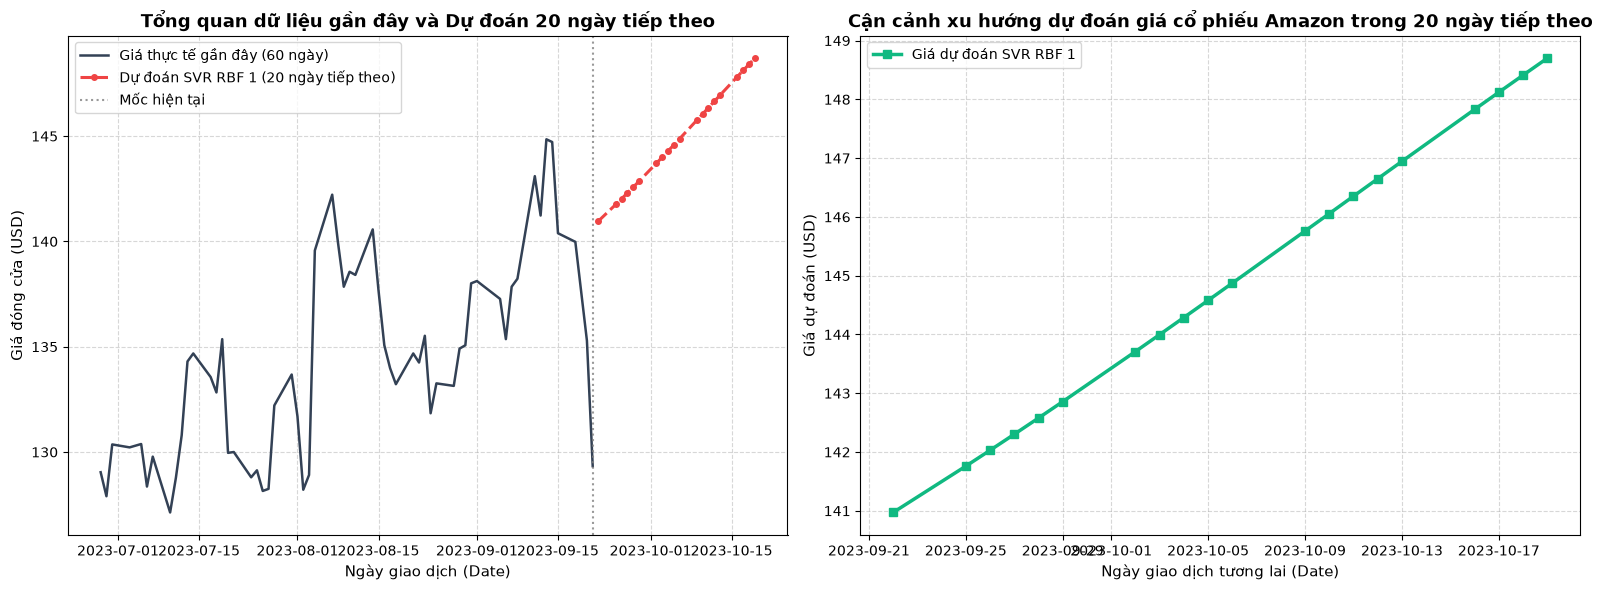

In [ ]:
# 6.1 Vẽ biểu đồ trực quan kết quả dự đoán cho 20 ngày tiếp theo
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

# Biểu đồ 1: Toàn cảnh 60 ngày giao dịch gần nhất và 20 ngày dự đoán tương lai
recent_data = data.iloc[-60:]
ax1.plot(recent_data['Date'], recent_data['Close'], color='#334155', linewidth=1.8, label='Giá thực tế gần đây (60 ngày)')
ax1.plot(future_dates, pred_future, color='#ef4444', linewidth=2.2, linestyle='--', marker='o', markersize=4, label='Dự đoán SVR RBF 1 (20 ngày tiếp theo)')
ax1.axvline(x=last_date, color='gray', linestyle=':', alpha=0.8, label='Mốc hiện tại')
ax1.set_title('Tổng quan dữ liệu gần đây và Dự đoán 20 ngày tiếp theo', fontsize=13, fontweight='bold')
ax1.set_xlabel('Ngày giao dịch (Date)', fontsize=11)
ax1.set_ylabel('Giá đóng cửa (USD)', fontsize=11)
ax1.grid(True, linestyle='--', alpha=0.5)
ax1.legend(loc='upper left')

# Biểu đồ 2: Cận cảnh xu hướng dự báo 20 ngày tiếp theo
ax2.plot(future_dates, pred_future, color='#10b981', linewidth=2.5, marker='s', markersize=6, label='Giá dự đoán SVR RBF 1')
ax2.set_title('Cận cảnh xu hướng dự đoán giá cổ phiếu Amazon trong 20 ngày tiếp theo', fontsize=13, fontweight='bold')
ax2.set_xlabel('Ngày giao dịch tương lai (Date)', fontsize=11)
ax2.set_ylabel('Giá dự đoán (USD)', fontsize=11)
ax2.grid(True, linestyle='--', alpha=0.5)
ax2.legend(loc='upper left')

plt.tight_layout()
plt.show()
